# El Perceptrón: compuertas AND y OR

El perceptrón es la unidad básica de una red neuronal. Tiene 4 componentes principales:

- **Valores de entrada** $x_1, x_2, \dots, x_n$
- **Pesos y sesgo (bias)** $w_1, w_2, \dots, w_n$ y $b$
- **Suma neta**: $z = \sum_i w_i x_i + b$
- **Función de activación**: en el perceptrón clásico es la función escalón

$$\hat{y} = \begin{cases} 1 & \text{si } z \ge 0 \\ 0 & \text{si } z < 0 \end{cases}$$

En esta libreta lo entrenamos para aprender las compuertas lógicas **AND** y **OR**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Los datos: tablas de verdad

Con dos entradas binarias solo hay 4 combinaciones posibles. Las salidas de AND y OR son:

| $x_1$ | $x_2$ | AND | OR |
|:---:|:---:|:---:|:---:|
| 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 |
| 1 | 0 | 0 | 1 |
| 1 | 1 | 1 | 1 |

In [2]:
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]])

y_and = np.array([0, 0, 0, 1])
y_or  = np.array([0, 1, 1, 1])

## 2. Implementación del perceptrón

La regla de aprendizaje del perceptrón (Rosenblatt) es muy sencilla. Para cada muestra $(x, y)$:

1. Calculamos la predicción $\hat{y}$.
2. Calculamos el error $e = y - \hat{y}$.
3. Actualizamos los pesos y el sesgo:

$$w_i \leftarrow w_i + \eta \cdot e \cdot x_i \qquad\qquad b \leftarrow b + \eta \cdot e$$

donde $\eta$ es la **tasa de aprendizaje**. Si el error es 0, no se cambia nada; si se equivocó, el hiperplano se mueve hacia el lado correcto.

In [3]:
class Perceptron:
    def __init__(self, n_entradas, tasa_aprendizaje=0.1, epocas=20, semilla=1):
        rng = np.random.default_rng(semilla)
        self.w = rng.normal(0, 0.5, n_entradas)
        self.b = 0.0
        self.eta = tasa_aprendizaje
        self.epocas = epocas
        self.errores_por_epoca = []

    def suma_neta(self, X):
        return X @ self.w + self.b

    def activacion(self, z):
        # función escalón
        return np.where(z >= 0, 1, 0)

    def predecir(self, X):
        return self.activacion(self.suma_neta(X))

    def entrenar(self, X, y):
        for _ in range(self.epocas):
            errores = 0
            for xi, yi in zip(X, y):
                error = yi - self.predecir(xi)
                self.w += self.eta * error * xi
                self.b += self.eta * error
                errores += int(error != 0)
            self.errores_por_epoca.append(errores)
            if errores == 0:   # ya clasifica todo bien
                break
        return self

## 3. Entrenamiento de la compuerta AND

In [4]:
p_and = Perceptron(n_entradas=2).entrenar(X, y_and)

print("Pesos:", p_and.w)
print("Sesgo:", p_and.b)
print("Épocas necesarias:", len(p_and.errores_por_epoca))
print("Errores por época:", p_and.errores_por_epoca)
print()
for xi, yi in zip(X, y_and):
    print(f"{xi} -> predicción: {p_and.predecir(xi)}  (esperado: {yi})")

Pesos: [0.1727921  0.21080907]
Sesgo: -0.30000000000000004
Épocas necesarias: 3
Errores por época: [2, 1, 0]

[0 0] -> predicción: 0  (esperado: 0)
[0 1] -> predicción: 0  (esperado: 0)
[1 0] -> predicción: 0  (esperado: 0)
[1 1] -> predicción: 1  (esperado: 1)


## 4. Entrenamiento de la compuerta OR

In [5]:
p_or = Perceptron(n_entradas=2).entrenar(X, y_or)

print("Pesos:", p_or.w)
print("Sesgo:", p_or.b)
print("Épocas necesarias:", len(p_or.errores_por_epoca))
print("Errores por época:", p_or.errores_por_epoca)
print()
for xi, yi in zip(X, y_or):
    print(f"{xi} -> predicción: {p_or.predecir(xi)}  (esperado: {yi})")

Pesos: [0.1727921  0.41080907]
Sesgo: -0.1
Épocas necesarias: 2
Errores por época: [1, 0]

[0 0] -> predicción: 0  (esperado: 0)
[0 1] -> predicción: 1  (esperado: 1)
[1 0] -> predicción: 1  (esperado: 1)
[1 1] -> predicción: 1  (esperado: 1)


## 5. Visualización de la frontera de decisión

El perceptrón separa el plano con una **línea recta**: $w_1 x_1 + w_2 x_2 + b = 0$. Los puntos de un lado son clase 1 y los del otro, clase 0. Por eso solo puede resolver problemas **linealmente separables**.

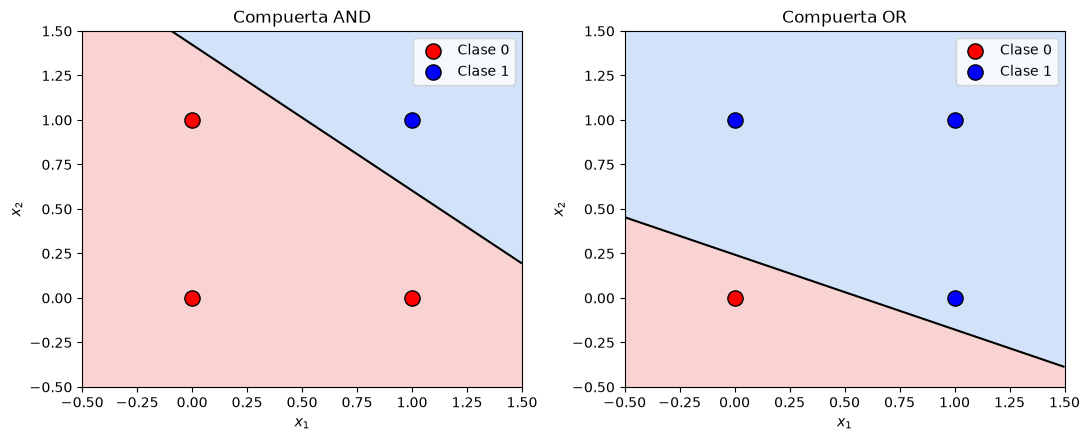

In [6]:
def graficar_frontera(modelo, X, y, titulo, ax):
    xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
    malla = np.c_[xx.ravel(), yy.ravel()]
    zz = modelo.predecir(malla).reshape(xx.shape)

    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#f4a6a6", "#a6c8f4"], alpha=0.5)
    ax.contour(xx, yy, modelo.suma_neta(malla).reshape(xx.shape), levels=[0], colors="k")
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="red", s=120, edgecolors="k", label="Clase 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="blue", s=120, edgecolors="k", label="Clase 1")
    ax.set_title(titulo)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.legend(loc="upper right")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
graficar_frontera(p_and, X, y_and, "Compuerta AND", axs[0])
graficar_frontera(p_or,  X, y_or,  "Compuerta OR",  axs[1])
plt.tight_layout()
plt.show()

## 6. Convergencia del entrenamiento

Para problemas linealmente separables, el **teorema de convergencia del perceptrón** garantiza que el algoritmo encuentra una solución en un número finito de pasos.

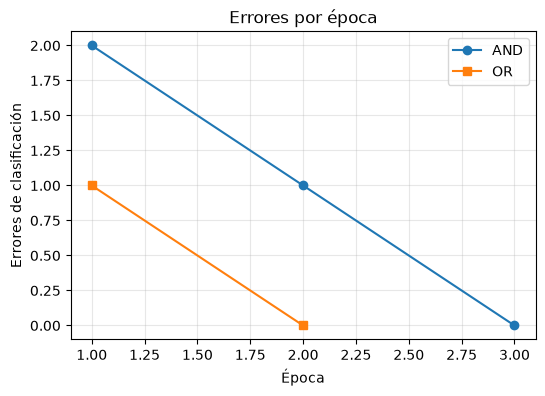

In [7]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(p_and.errores_por_epoca) + 1), p_and.errores_por_epoca, "o-", label="AND")
plt.plot(range(1, len(p_or.errores_por_epoca) + 1),  p_or.errores_por_epoca,  "s-", label="OR")
plt.xlabel("Época"); plt.ylabel("Errores de clasificación")
plt.title("Errores por época")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 7. Conclusiones

- Un perceptrón calcula una suma ponderada de las entradas, le suma un sesgo y aplica una función escalón.
- Aprende ajustando pesos y sesgo cada vez que se equivoca.
- AND y OR son **linealmente separables**: una sola línea recta basta, así que el perceptrón converge.
- Hay problemas que **no** se pueden separar con una recta; el ejemplo clásico es **XOR**, que veremos en la siguiente libreta (`perceptron_xor.ipynb`).